# ColorChecker Reflectance vs Ground Truth (big / small)

- 측정값: `big_small_colorchecker.xlsx` (Radiance, 380–1000 nm, 1 nm)
  - big patch: `0`–`23`, small patch: `small_0`–`small_23`, 기준: `Spectralon`
- Reflectance = patch radiance / Spectralon radiance
- Ground truth: `MacbethColorChecker 3.csv` (380–780 nm, 5 nm, patch 1–24)
- 측정 patch `i` (0–23) ↔ GT patch `i+1` (1–24)

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MEAS_PATH = 'big_small_colorchecker.xlsx'
GT_PATH = 'MacbethColorChecker 3.csv'

PATCH_NAMES = ['dark skin', 'light skin', 'blue sky', 'foliage', 'blue flower', 'bluish green',
               'orange', 'purplish blue', 'moderate red', 'purple', 'yellow green', 'orange yellow',
               'blue', 'green', 'red', 'yellow', 'magenta', 'cyan',
               'white', 'neutral 8', 'neutral 6.5', 'neutral 5', 'neutral 3.5', 'black']
# 각 patch의 대략적인 sRGB 색 (plot 색상용)
PATCH_RGB = ['#735244', '#c29682', '#627a9d', '#576c43', '#8580b1', '#67bdaa',
             '#d67e2c', '#505ba6', '#c15a63', '#5e3c6c', '#9dbc40', '#e0a32e',
             '#383d96', '#469449', '#af363c', '#e7c71f', '#bb5695', '#0885a1',
             '#f3f3f2', '#c8c8c8', '#a0a0a0', '#7a7a79', '#555555', '#343434']

## 1. 데이터 로드

In [6]:
# 측정 데이터: row 3 = patch 이름, row 15부터 = 스펙트럼
raw = pd.read_excel(MEAS_PATH, header=None)
names = [str(n) for n in raw.iloc[3, 1:]]
meas = raw.iloc[15:, :].astype(float)
meas.columns = ['wavelength'] + names
meas = meas.set_index('wavelength')
meas = meas.loc[380:1000]

# Reflectance = patch / Spectralon
refl_all = meas.drop(columns='Spectralon').div(meas['Spectralon'], axis=0)
refl_big = refl_all[[str(i) for i in range(24)]]            # columns: '0'..'23'
refl_small = refl_all[[f'small_{i}' for i in range(24)]]
refl_small.columns = [str(i) for i in range(24)]            # big과 같은 key로 맞춤

# Ground truth
gt = pd.read_csv(GT_PATH, skiprows=2).iloc[:, :25]
gt = gt.set_index('wavelength').astype(float)
gt.columns = [str(int(c) - 1) for c in gt.columns]  # 1~24 -> 0~23 으로 맞춤

print('big   reflectance:', refl_big.shape, refl_big.index.min(), '-', refl_big.index.max(), 'nm')
print('small reflectance:', refl_small.shape)
print('ground truth     :', gt.shape, gt.index.min(), '-', gt.index.max(), 'nm')

big   reflectance: (621, 24) 380.0 - 1000.0 nm
small reflectance: (621, 24)
ground truth     : (81, 24) 380 - 780 nm


## 2. Plot 함수

In [7]:
# curves: list of (DataFrame, label, plot kwargs). 각 DataFrame의 column은 '0'..'23'
def plot_grid(curves, title):
    fig, axes = plt.subplots(4, 6, figsize=(24, 15), sharex=True, sharey=True)
    for i, ax in enumerate(axes.flat):
        k = str(i)
        for df, label, kw in curves:
            ax.plot(df.index, df[k], label=label, **kw)
        ax.set_facecolor(PATCH_RGB[i] + '40')
        ax.set_title(f'{i}: {PATCH_NAMES[i]}', fontsize=12)
        ax.axvline(780, color='gray', lw=0.6, ls=':')
        ax.grid(alpha=0.3)
        ax.set_xlim(380, 1000)
        ax.set_ylim(0, 1.2)
    for ax in axes[-1]:
        ax.set_xlabel('Wavelength [nm]')
    for ax in axes[:, 0]:
        ax.set_ylabel('Reflectance')
    axes[0, 0].legend(loc='upper left', fontsize=9)
    fig.suptitle(title, fontsize=16)
    fig.tight_layout()
    plt.show()


def plot_overview(refl, title):
    fig, axes = plt.subplots(1, 2, figsize=(20, 7), sharey=True)
    for i in range(24):
        c = PATCH_RGB[i] if i != 18 else '#bbbbbb'  # white는 잘 보이도록
        axes[0].plot(refl.index, refl[str(i)], color=c, lw=1.4, label=str(i))
        axes[1].plot(gt.index, gt[str(i)], color=c, lw=1.4, label=str(i))
    axes[0].set_title(f'{title} (380–1000 nm)')
    axes[1].set_title('Ground truth (380–780 nm)')
    for ax in axes:
        ax.set_xlim(380, 1000)
        ax.set_xlabel('Wavelength [nm]')
        ax.grid(alpha=0.3)
    axes[0].set_ylabel('Reflectance')
    axes[1].legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
    fig.tight_layout()
    plt.show()


# GT 파장 위치(380–780 nm, 5 nm)에서 RMSE / MAE
def error_table(refl):
    diff = refl.reindex(gt.index) - gt
    return pd.DataFrame({'RMSE': np.sqrt((diff ** 2).mean()).values,
                         'MAE': diff.abs().mean().values}, index=range(24))


GT_KW = dict(color='tab:red', ls='--', marker='o', ms=2.5, lw=1.2)
BIG_KW = dict(color='k', lw=1.6)
SMALL_KW = dict(color='tab:blue', lw=1.6)

## 3. Big patch (0–23) vs Ground truth

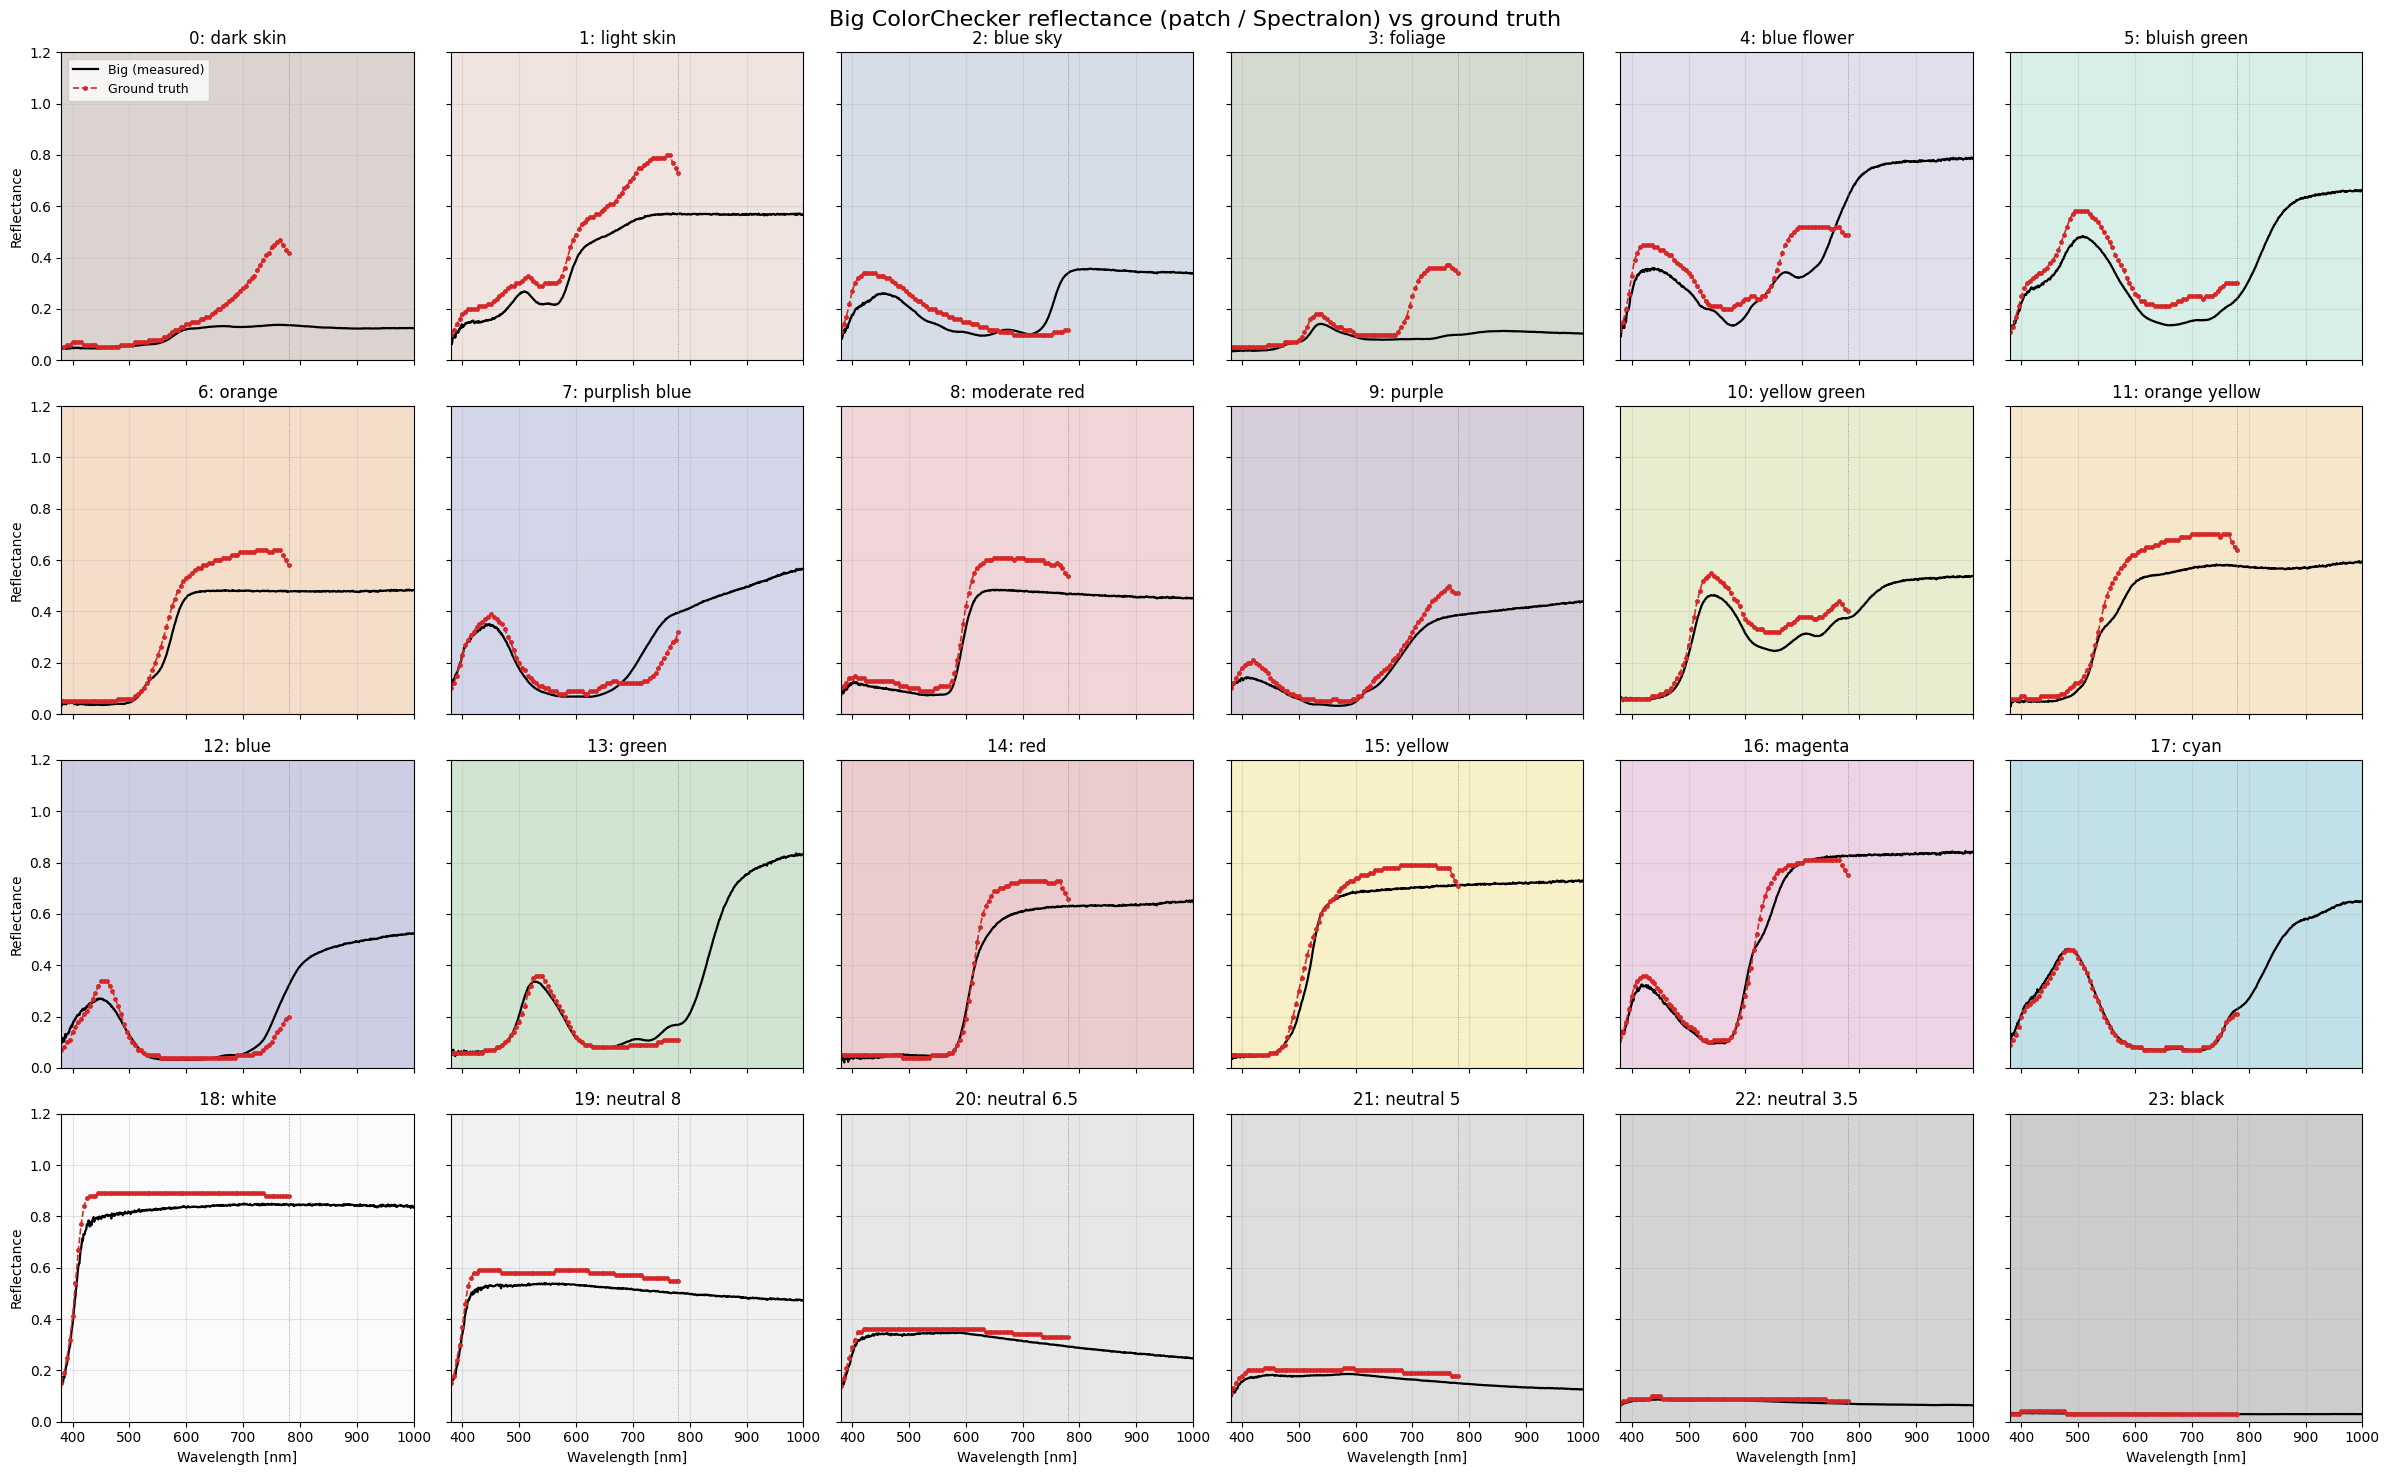

In [8]:
plot_grid([(refl_big, 'Big (measured)', BIG_KW), (gt, 'Ground truth', GT_KW)],
          'Big ColorChecker reflectance (patch / Spectralon) vs ground truth')

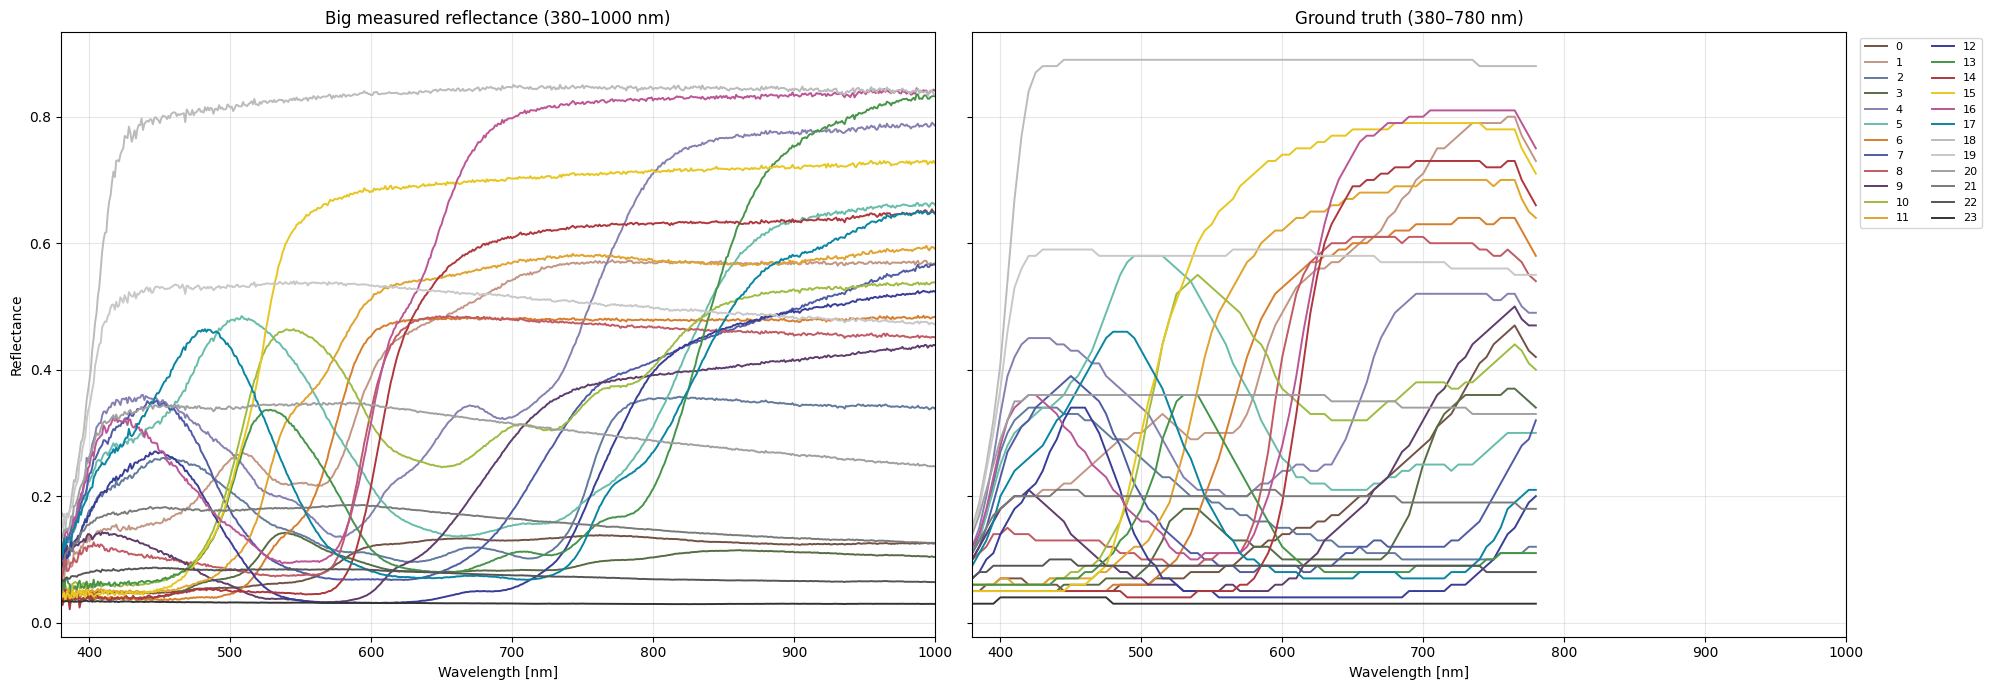

In [9]:
plot_overview(refl_big, 'Big measured reflectance')

## 4. Small patch (small_0–small_23) vs Ground truth

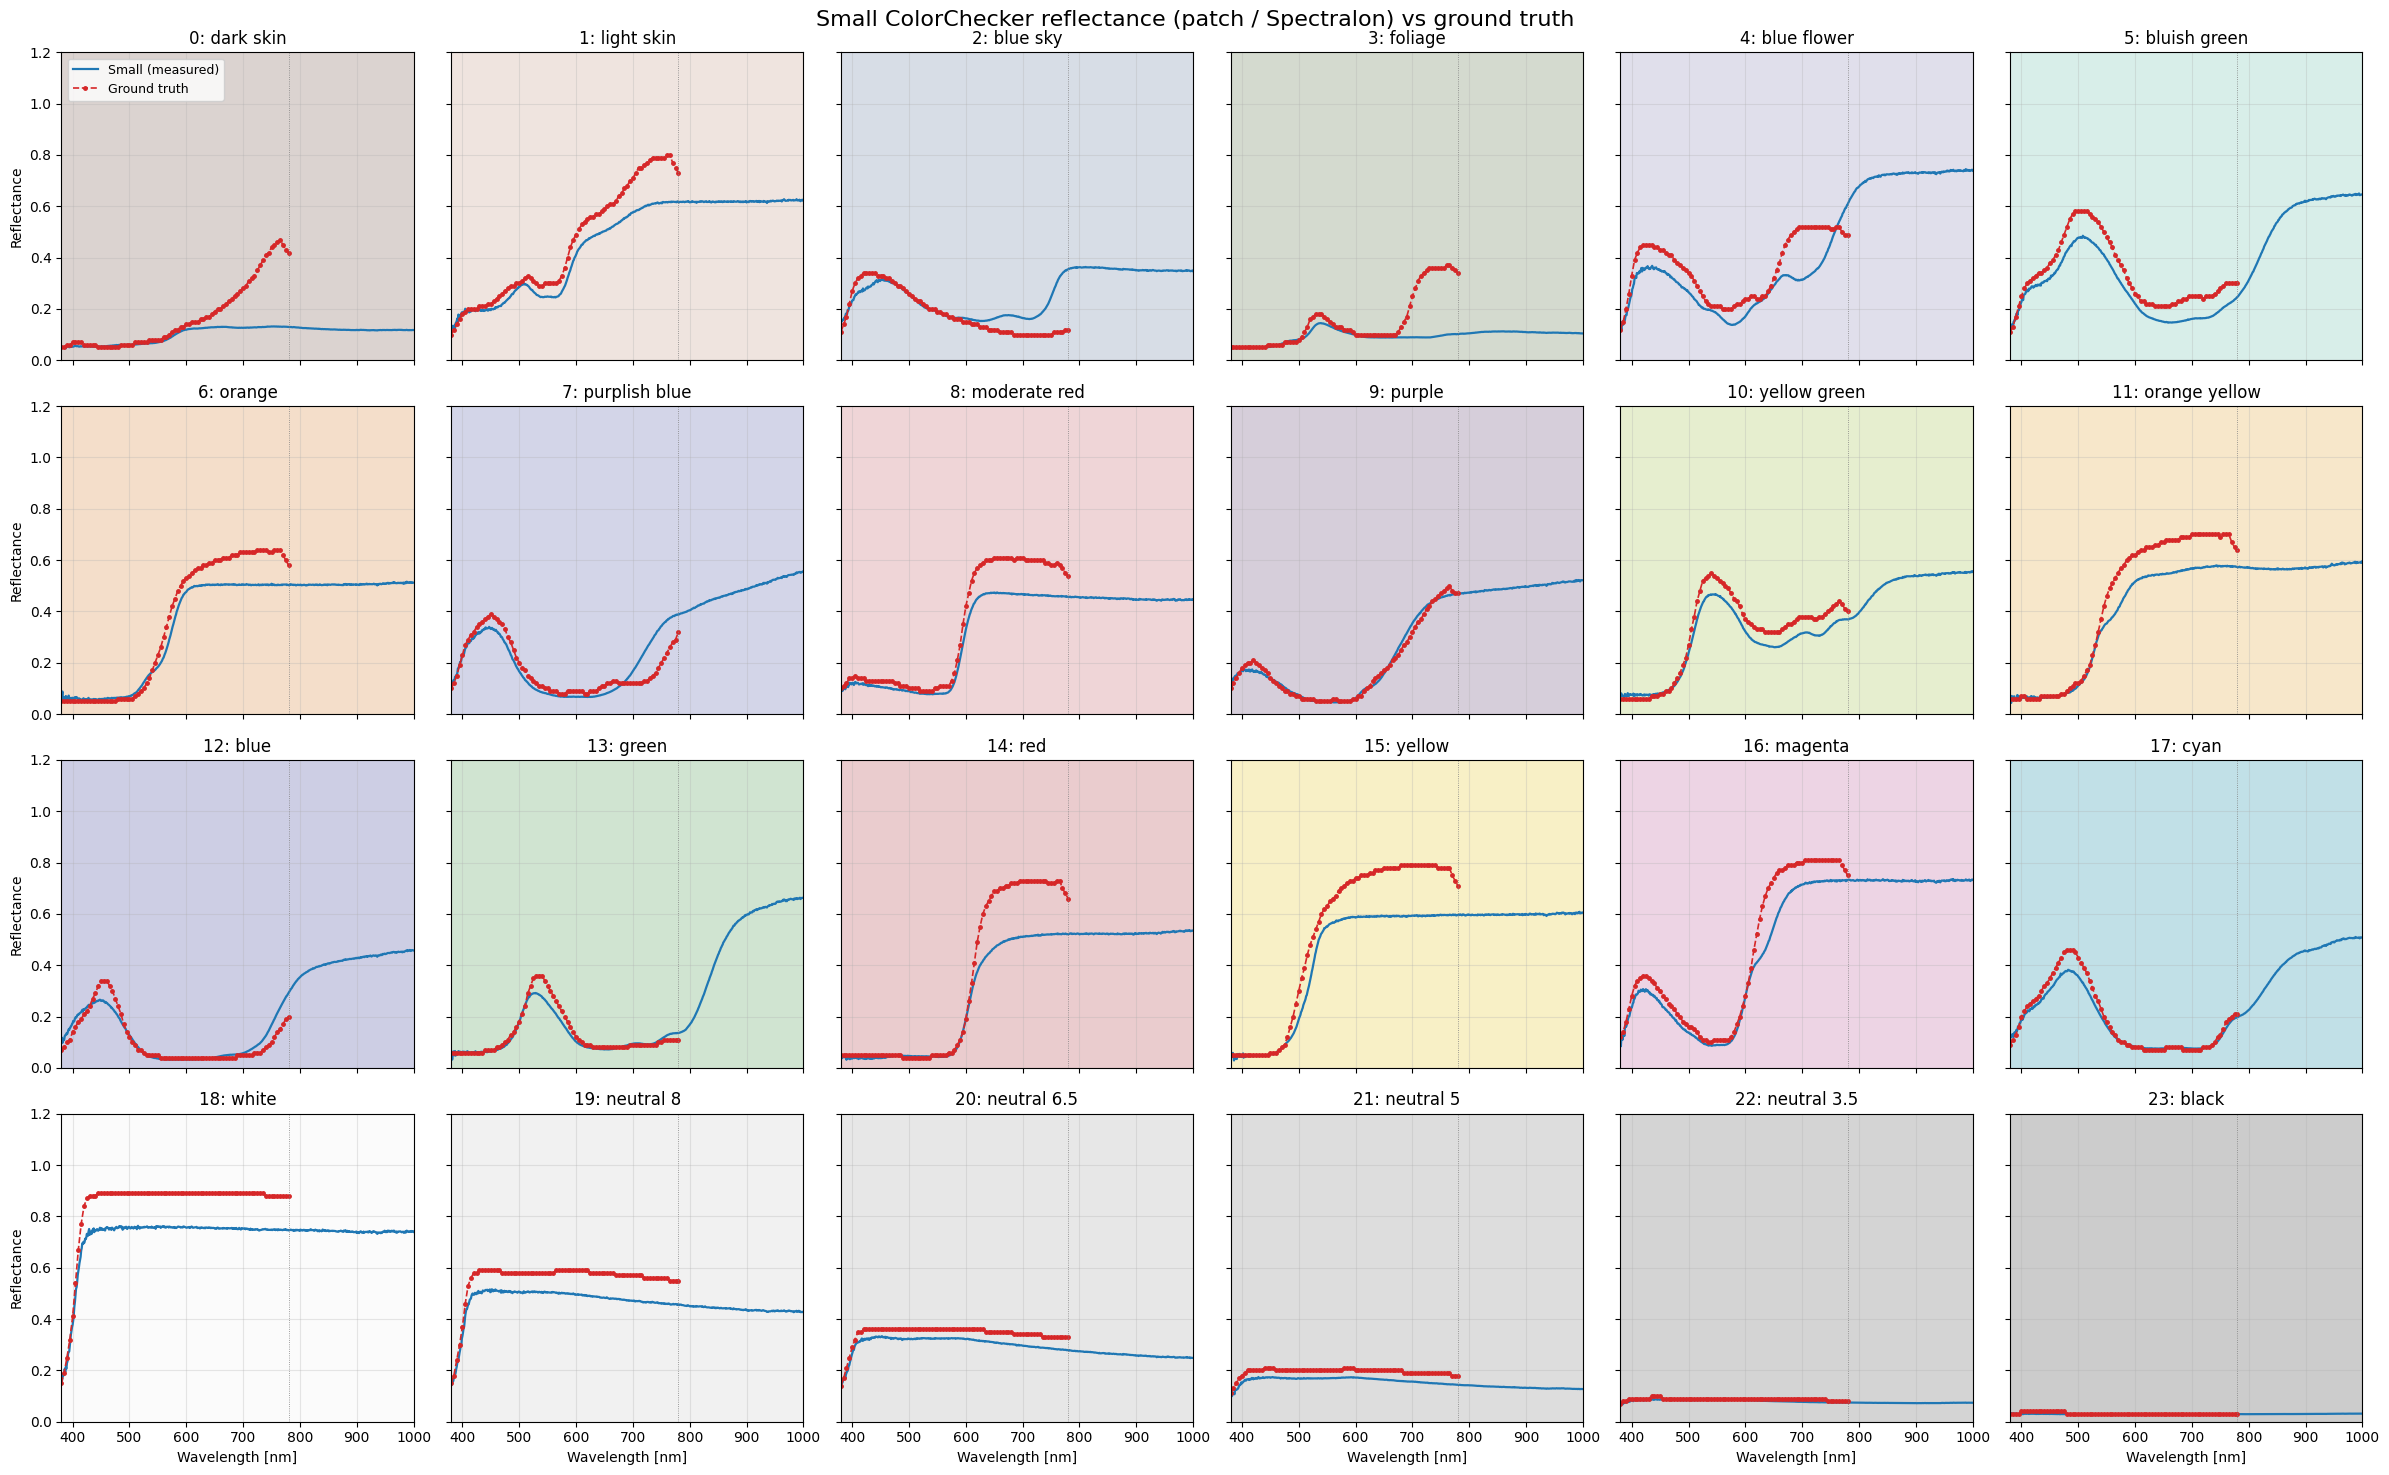

In [10]:
plot_grid([(refl_small, 'Small (measured)', SMALL_KW), (gt, 'Ground truth', GT_KW)],
          'Small ColorChecker reflectance (patch / Spectralon) vs ground truth')

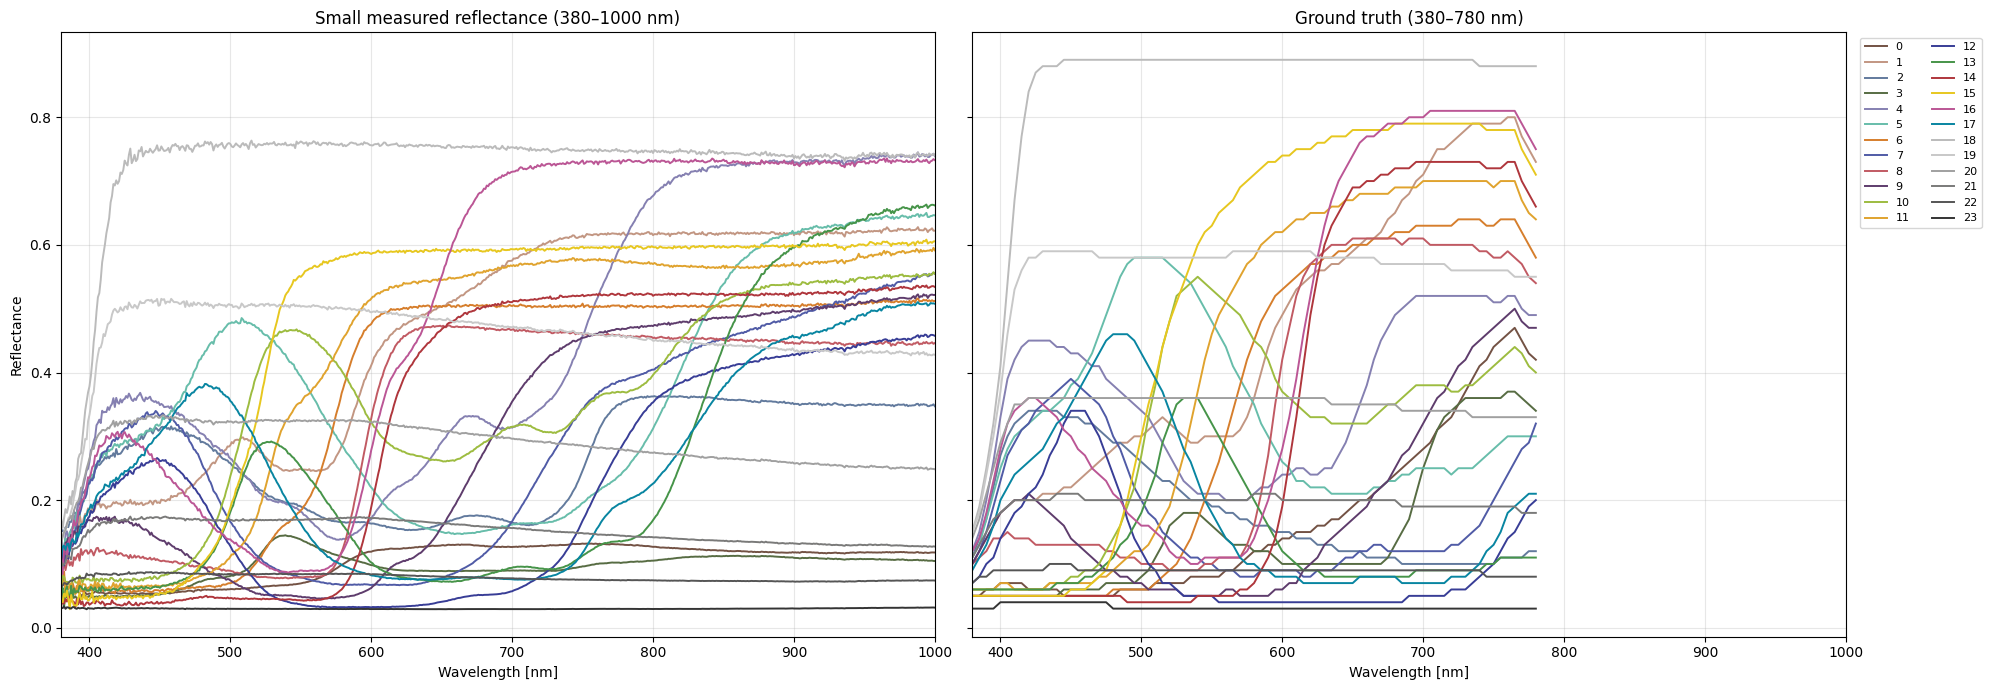

In [11]:
plot_overview(refl_small, 'Small measured reflectance')

## 5. Big vs Small vs Ground truth

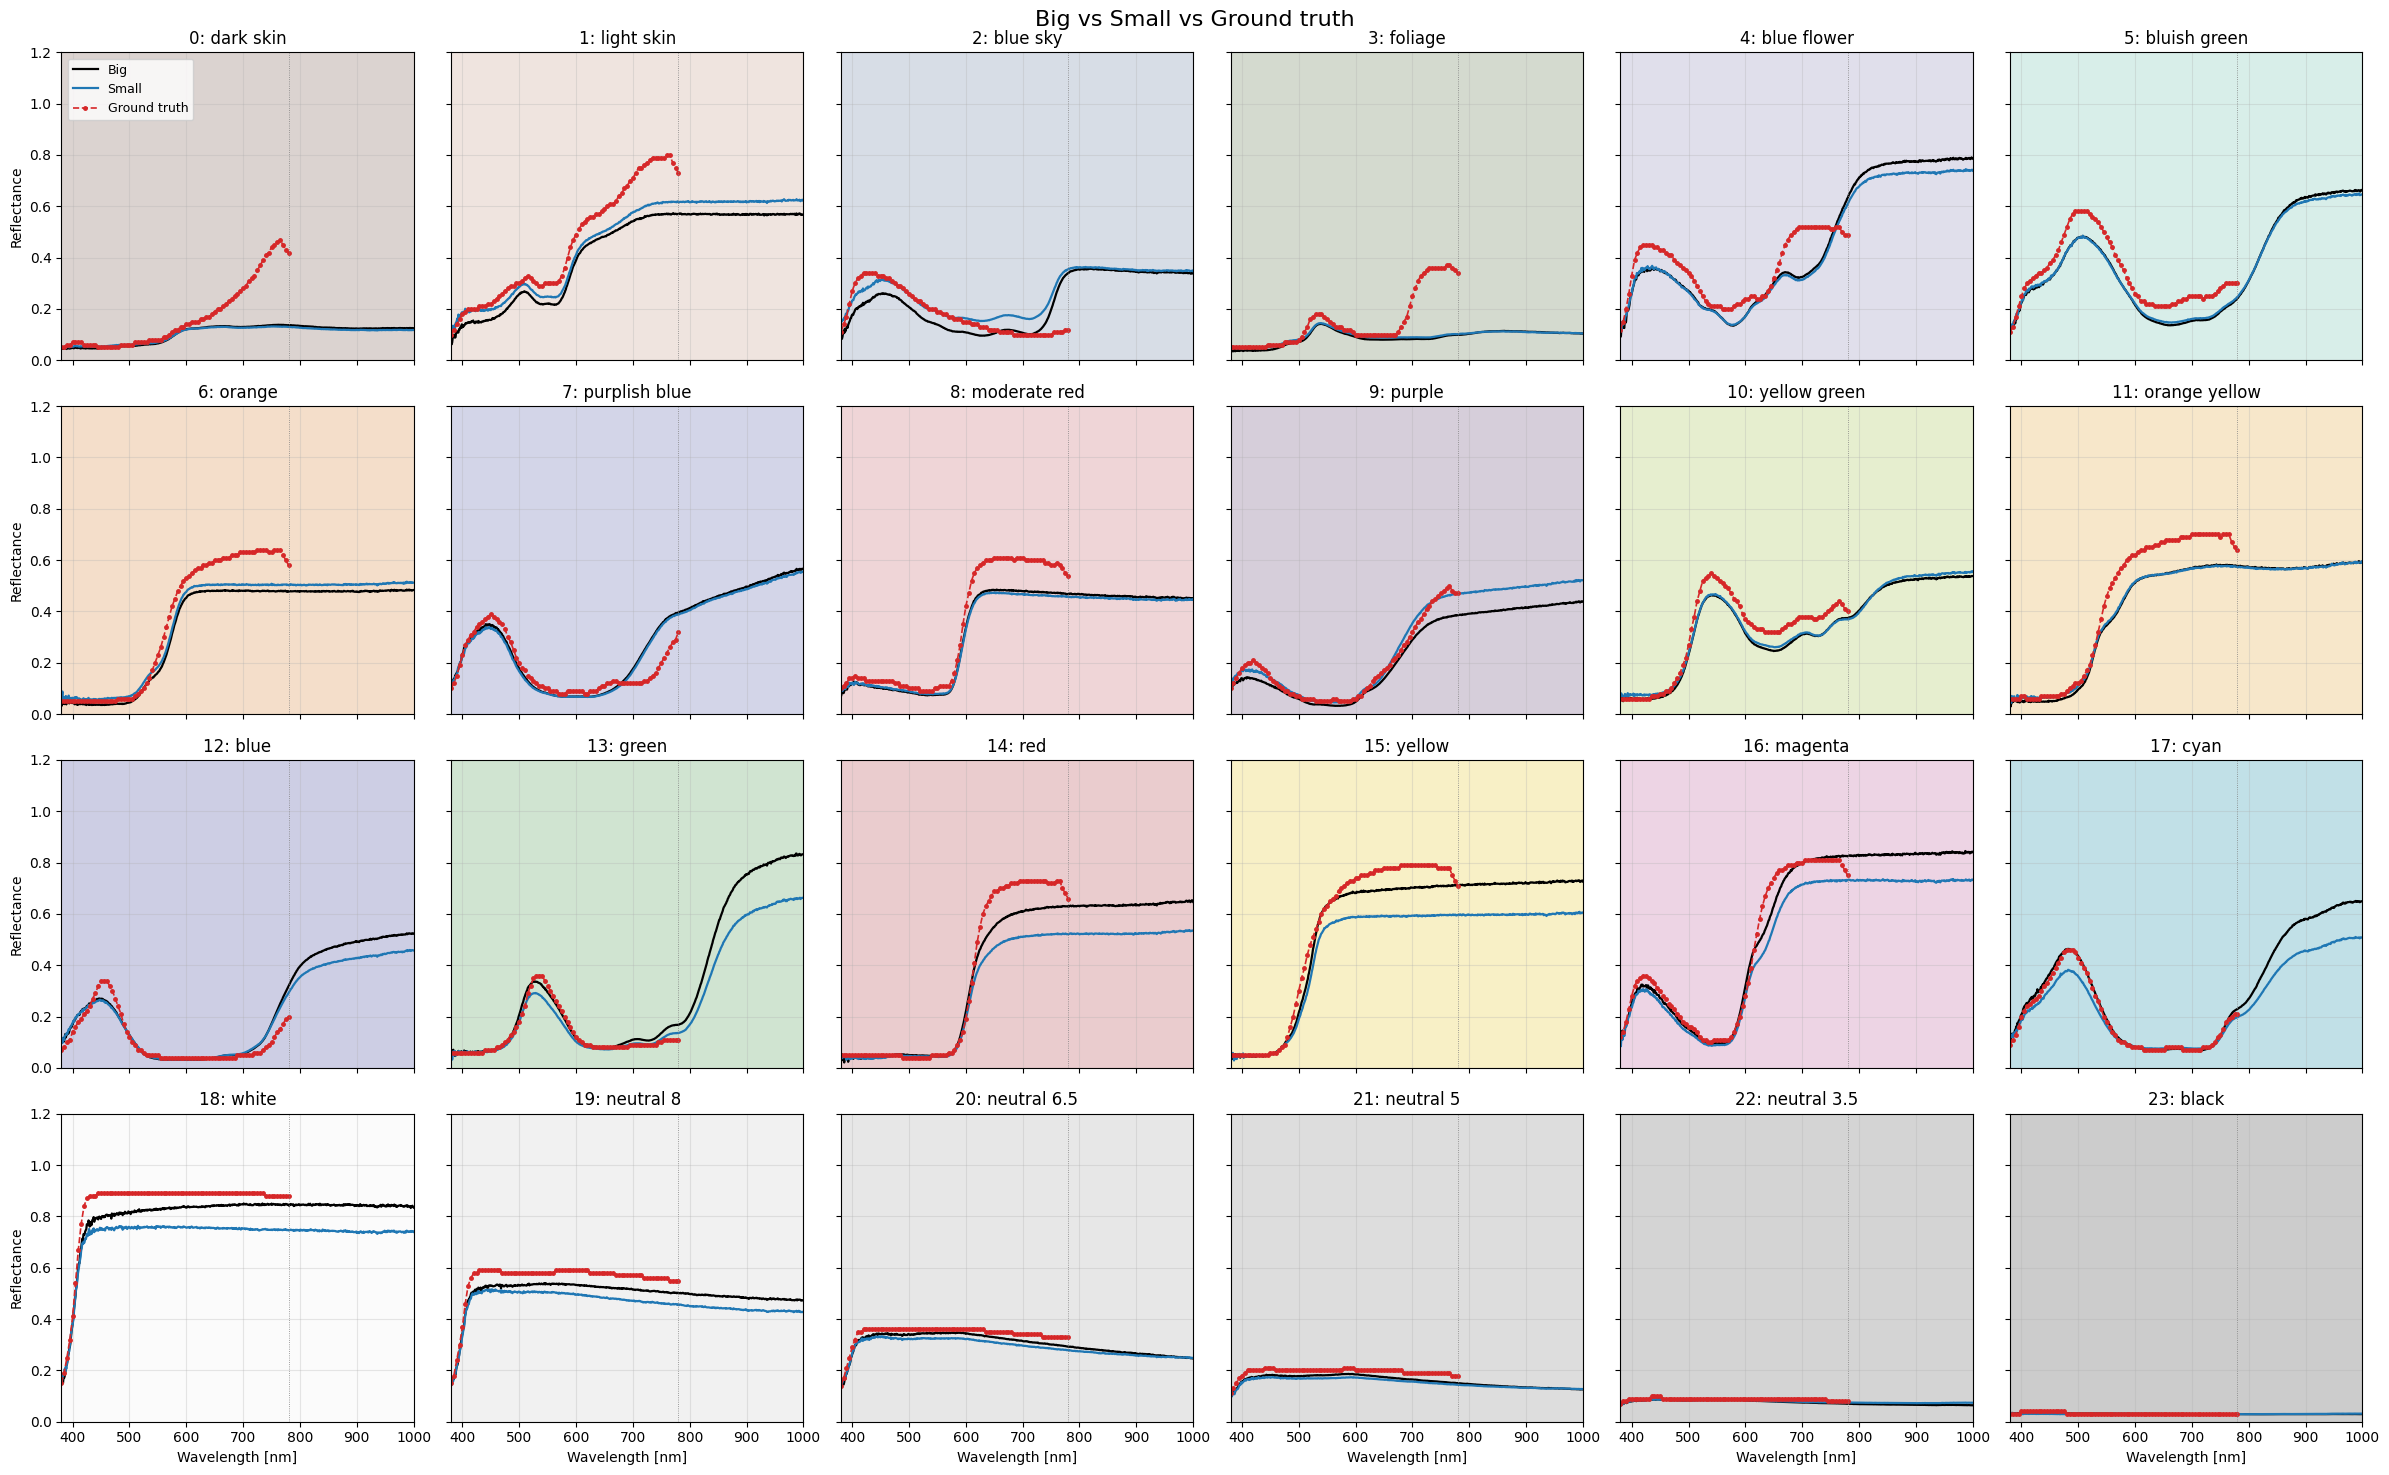

In [12]:
plot_grid([(refl_big, 'Big', BIG_KW), (refl_small, 'Small', SMALL_KW), (gt, 'Ground truth', GT_KW)],
          'Big vs Small vs Ground truth')

## 6. 오차 (380–780 nm, GT 파장 위치에서)

,name,RMSE_big,RMSE_small,MAE_big,MAE_small
0,dark skin,0.1248,0.1273,0.0747,0.0749
1,light skin,0.1215,0.0930,0.1070,0.0752
2,blue sky,0.0743,0.0729,0.0576,0.0465
3,foliage,0.1195,0.1164,0.0707,0.0638
4,blue flower,0.0909,0.0938,0.0757,0.0778
5,bluish green,0.0762,0.0729,0.0718,0.0681
6,orange,0.0956,0.0780,0.0758,0.0612
7,purplish blue,0.0602,0.0592,0.0421,0.0443
8,moderate red,0.0812,0.0883,0.0671,0.0704
9,purple,0.0450,0.0171,0.0349,0.0131


mean RMSE  big: 0.0607   small: 0.0712


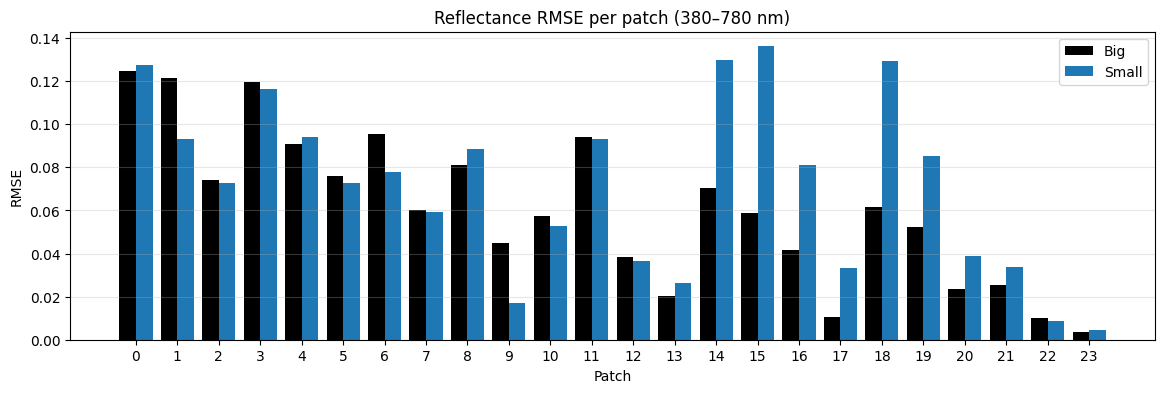

In [13]:
err_big = error_table(refl_big)
err_small = error_table(refl_small)
err = pd.DataFrame({'name': PATCH_NAMES,
                    'RMSE_big': err_big['RMSE'], 'RMSE_small': err_small['RMSE'],
                    'MAE_big': err_big['MAE'], 'MAE_small': err_small['MAE']})
display(err.round(4))
print('mean RMSE  big: %.4f   small: %.4f' % (err['RMSE_big'].mean(), err['RMSE_small'].mean()))

x = np.arange(24)
w = 0.4
plt.figure(figsize=(14, 4))
plt.bar(x - w/2, err['RMSE_big'], w, color='k', label='Big')
plt.bar(x + w/2, err['RMSE_small'], w, color='tab:blue', label='Small')
plt.xticks(x)
plt.xlabel('Patch'); plt.ylabel('RMSE'); plt.title('Reflectance RMSE per patch (380–780 nm)')
plt.legend(); plt.grid(axis='y', alpha=0.3)
plt.show()